# ShopExpress — Modélisation avec le dataset original

**Objectif :** entraîner, comparer et optimiser des modèles de classification avec le véritable fichier `Original.csv`, sans variables synthétiques.

**Cible :** `Reached.on.Time_Y.N` — `1` = commande livrée en retard ; `0` = commande livrée à temps.

**Règle méthodologique :** séparation stratifiée 70 % entraînement / 15 % validation / 15 % test. Le test reste réservé à l'évaluation finale.


## Guide d’exécution — livrable Jalon 2

1. Déposer `Original.csv` dans le même dossier que ce notebook.
2. Ouvrir le notebook dans Jupyter ou Google Colab et exécuter les cellules dans l’ordre.
3. Le modèle utilise uniquement les 10 variables originales ; `ID` est exclu.
4. Le seuil est choisi sur validation avec une cible de rappel de 90 % (modifiable dans la cellule 27).
5. Le test est réservé à l’évaluation finale. Ne pas ajuster le seuil à partir du test.
6. Les résultats et le modèle sont écrits dans `resultats_shopexpress/`.



## 1. Installation et importation

Si les bibliothèques sont déjà installées dans votre environnement, vous pouvez simplement exécuter la cellule suivante.

In [1]:
%pip install -q pandas numpy matplotlib scikit-learn joblib mlflow dagshub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve, RocCurveDisplay
)
from sklearn.inspection import permutation_importance
from scipy.stats import randint
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
TARGET = "Reached.on.Time_Y.N"
OUTPUT_DIR = "resultats_shopexpress"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Dossier de résultats :", os.path.abspath(OUTPUT_DIR))


pandas: 3.1.0
scikit-learn: 1.9.1
Dossier de résultats : c:\Users\nadia\OneDrive - Collège la Cité\Bureau\Tous_dossiers\Session3\Projet_IA_M&D\Delais_livraison\resultats_shopexpress


## 2. Chargement du dataset original

In [3]:
DATA_PATH = "Original.csv"  # dataset original fourni
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Original.csv introuvable. Placez Original.csv dans le même dossier que original.ipynb."
    )

df = pd.read_csv(DATA_PATH)
print("Dimensions du fichier :", df.shape)
display(df.head())
print("\nColonnes disponibles :")
print(df.columns.tolist())

Dimensions du fichier : (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1



Colonnes disponibles :
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


Le fichier utilisé est le véritable `Original.csv` fourni séparément. Il contient les 10 variables explicatives originales, la colonne `ID` et la cible. Aucune variable synthétique n'est créée ni importée dans cette expérience. La colonne `ID` est exclue des prédicteurs.


In [4]:
original_features_expected = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Product_importance",
    "Gender",
    "Discount_offered",
    "Weight_in_gms"
]

assert TARGET in df.columns, f"La cible {TARGET} est absente du fichier."
missing_original = [c for c in original_features_expected if c not in df.columns]
if missing_original:
    raise ValueError(f"Variables originales manquantes : {missing_original}")

# Utiliser uniquement les 10 variables originales et la cible.
# ID et toute éventuelle colonne supplémentaire sont exclus.
keep_columns = original_features_expected + [TARGET]
df_model = df[keep_columns].copy()

df_model = df_model.dropna(subset=[TARGET]).copy()
classes = set(pd.to_numeric(df_model[TARGET], errors="coerce").dropna().unique())
if not classes.issubset({0, 1, 0.0, 1.0}):
    raise ValueError(f"Valeurs inattendues dans la cible : {classes}")
df_model[TARGET] = pd.to_numeric(df_model[TARGET]).astype(int)

original_features = original_features_expected.copy()
print("Dataset utilisé :", DATA_PATH)
print("Nombre de commandes :", len(df_model))
print("Nombre de variables explicatives :", len(original_features))
print("Variables utilisées :", original_features)
print("Colonnes exclues :", [c for c in df.columns if c not in keep_columns])
print("\\nConvention cible : 0 = à temps ; 1 = en retard")
display(df_model[TARGET].value_counts().sort_index().rename(
    index={0: "À temps (0)", 1: "En retard (1)"}
).to_frame("Nombre de commandes"))


Dataset utilisé : Original.csv
Nombre de commandes : 10999
Nombre de variables explicatives : 10
Variables utilisées : ['Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms']
Colonnes exclues : ['ID']
\nConvention cible : 0 = à temps ; 1 = en retard


,Nombre de commandes
Reached.on.Time_Y.N,
À temps (0),4436
En retard (1),6563


## 4. Exploration descriptive du dataset original

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Warehouse_block,10999,5,F,3666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode_of_Shipment,10999,3,Ship,7462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_care_calls,10999.0,NaN,NaN,NaN,4.054459,1.14149,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,NaN,NaN,NaN,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,NaN,NaN,NaN,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,NaN,NaN,NaN,3.567597,1.52286,2.0,3.0,3.0,4.0,10.0
Product_importance,10999,3,low,5297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10999,2,F,5545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_offered,10999.0,NaN,NaN,NaN,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,NaN,NaN,NaN,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0


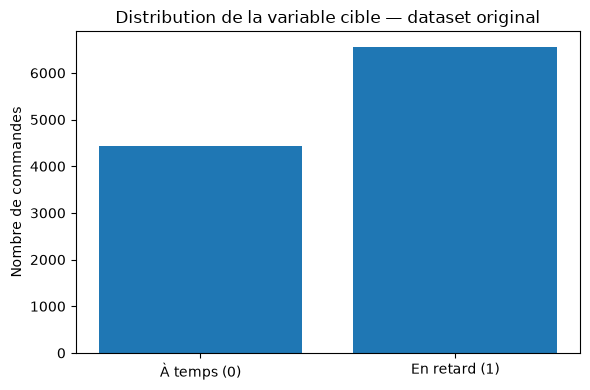

,Valeurs manquantes
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0
Weight_in_gms,0


In [5]:
display(df_model[original_features].describe(include="all").T)

class_counts = df_model[TARGET].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["À temps (0)", "En retard (1)"], [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Distribution de la variable cible — dataset original")
plt.ylabel("Nombre de commandes")
plt.tight_layout()
plt.show()

missing = df_model.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Valeurs manquantes"))

### Graphiques exploratoires des variables originales\nLes graphiques ci-dessous portent uniquement sur les colonnes présentes dans `Original.csv`.\n

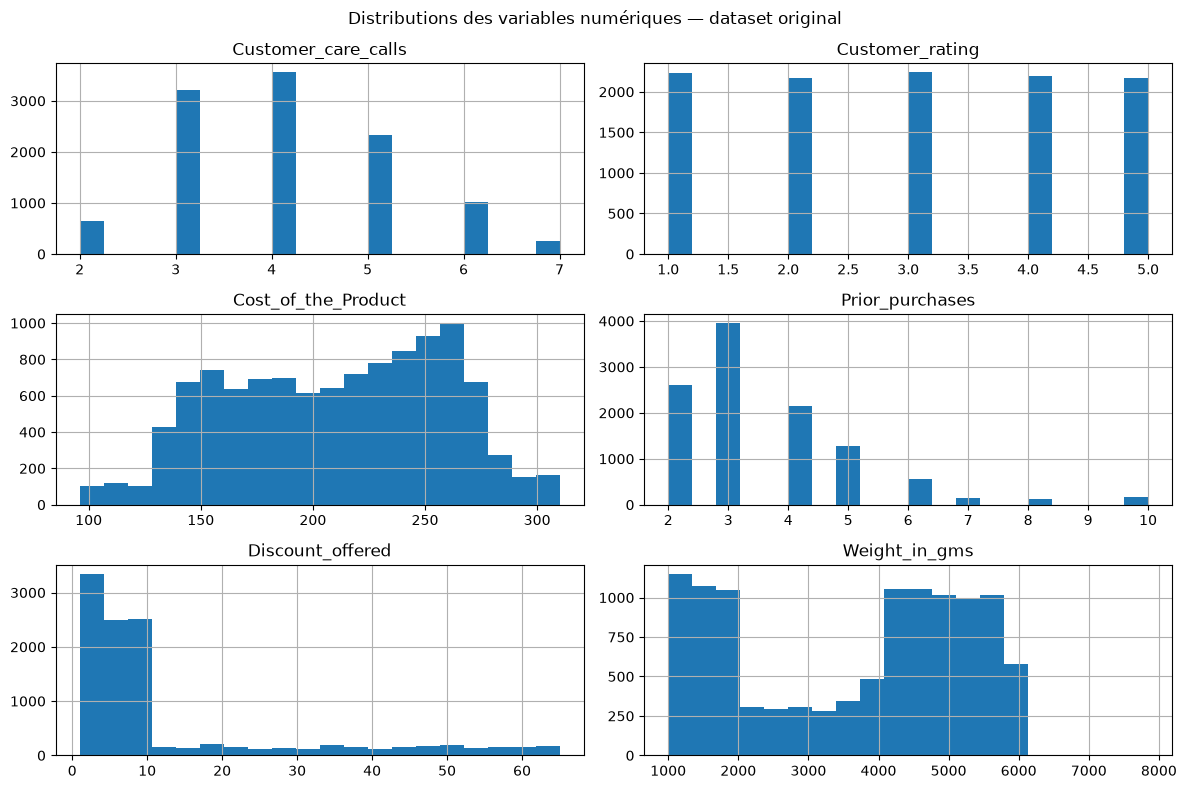

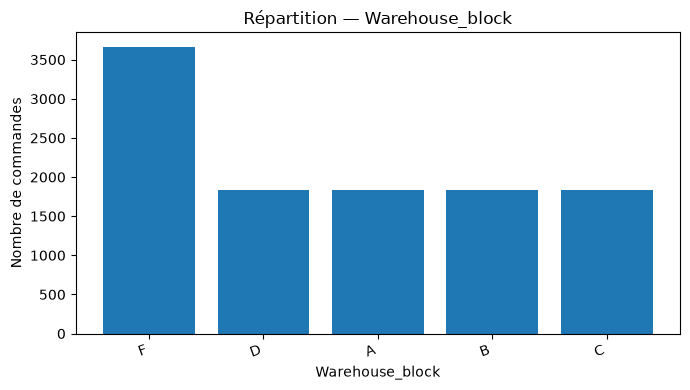

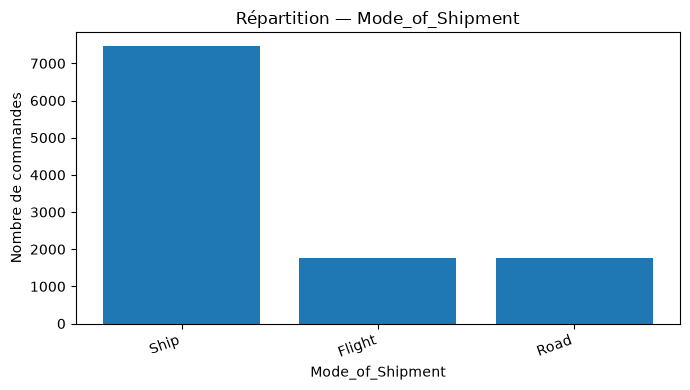

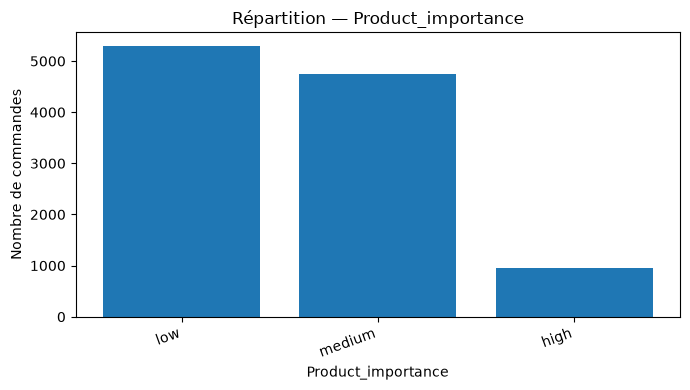

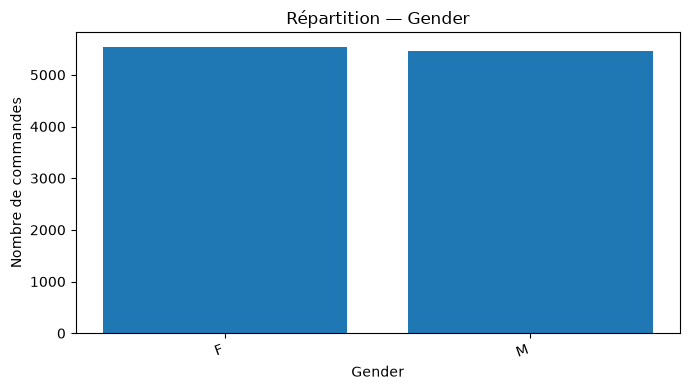

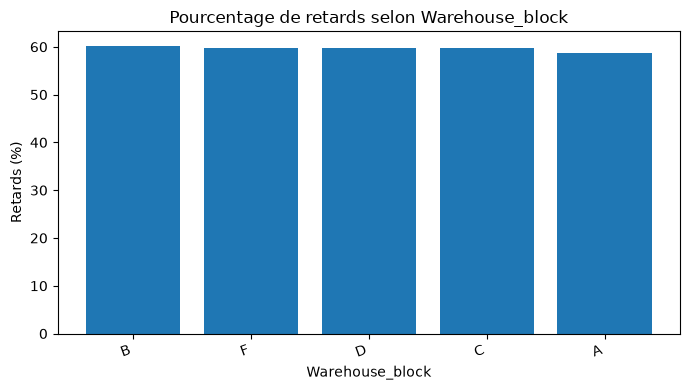

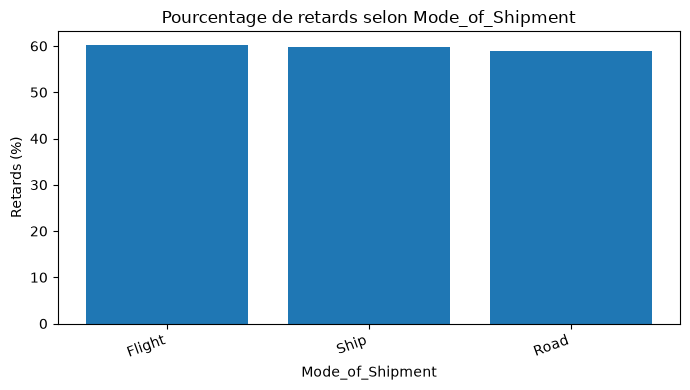

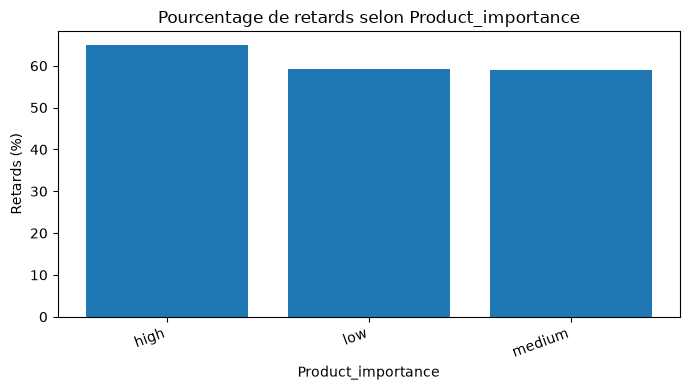

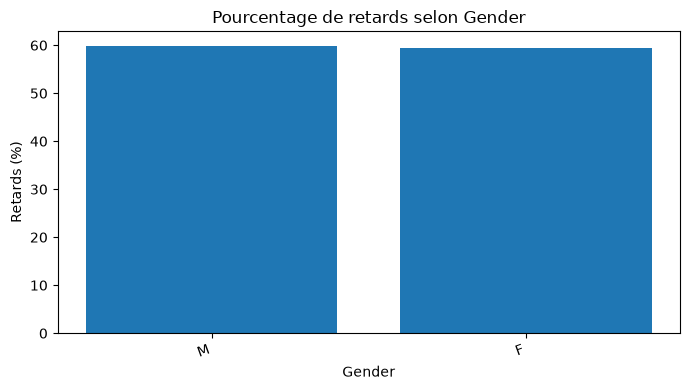

In [6]:
# Distributions des variables numériques originales
numeric_cols = df_model[original_features].select_dtypes(include=np.number).columns.tolist()
df_model[numeric_cols].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distributions des variables numériques — dataset original")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "distributions_numeriques_original.png"), dpi=150)
plt.show()

# Répartition des variables catégorielles originales
categorical_cols = df_model[original_features].select_dtypes(exclude=np.number).columns.tolist()
for col in categorical_cols:
    counts = df_model[col].value_counts()
    plt.figure(figsize=(7, 4))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title(f"Répartition — {col}")
    plt.xlabel(col)
    plt.ylabel("Nombre de commandes")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"repartition_{col}.png"), dpi=150)
    plt.show()

# Taux de retard par variable catégorielle
for col in categorical_cols:
    rates = df_model.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    plt.figure(figsize=(7, 4))
    plt.bar(rates.index.astype(str), rates.values)
    plt.title(f"Pourcentage de retards selon {col}")
    plt.xlabel(col)
    plt.ylabel("Retards (%)")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"retards_par_{col}.png"), dpi=150)
    plt.show()


## 5. Séparation des données

Nous reprenons une séparation stratifiée de 70 % entraînement, 15 % validation et 15 % test, avec `random_state=42`. Le jeu de test reste réservé à l’évaluation finale. Cette séparation doit être conservée pour comparer les résultats aux expériences précédentes.

In [7]:
X = df_model[original_features].copy()
y = df_model[TARGET].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Entraînement :", X_train.shape)
print("Validation :", X_valid.shape)
print("Test :", X_test.shape)
print("\nProportions de la classe 1 :")
print("Train :", round(y_train.mean(), 4), "Validation :", round(y_valid.mean(), 4), "Test :", round(y_test.mean(), 4))

Entraînement : (7699, 10)
Validation : (1650, 10)
Test : (1650, 10)

Proportions de la classe 1 :
Train : 0.5967 Validation : 0.597 Test : 0.5964


## 6. Prétraitement et fonction d’évaluation

Le prétraitement est placé dans un pipeline afin que l’imputation, l’encodage et la standardisation soient ajustés uniquement sur les données d’entraînement de chaque pli de validation croisée.

In [8]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Variables numériques :", numeric_features)
print("Variables catégorielles :", categorical_features)

def evaluate_predictions(y_true, y_pred, y_probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision retard (classe 1)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall retard (classe 1)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score retard (classe 1)": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability)
    }

Variables numériques : ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
Variables catégorielles : ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


## 7. Modèles de référence sur les variables originales

Nous évaluons les trois modèles de référence déjà utilisés (régression logistique, arbre de décision et Random Forest), puis Gradient Boosting afin de pouvoir vérifier s’il reste performant sans les variables synthétiques.

In [9]:
baseline_models = {
    "Régression logistique": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Arbre de décision": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

baseline_results = []
baseline_fitted = {}
for name, estimator in baseline_models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_valid)
    prob = pipe.predict_proba(X_valid)[:, 1]
    metrics = evaluate_predictions(y_valid, pred, prob)
    metrics["Modèle"] = name
    baseline_results.append(metrics)
    baseline_fitted[name] = pipe

baseline_df = pd.DataFrame(baseline_results).set_index("Modèle").sort_values("F1-score retard (classe 1)", ascending=False)
display(baseline_df.round(4))

,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC
Modèle,,,,,
Régression logistique,0.6442,0.7163,0.6690,0.6919,0.7247
Arbre de décision,0.6279,0.6959,0.6690,0.6822,0.6180
Random Forest,0.6352,0.7350,0.6081,0.6656,0.7167
Gradient Boosting,0.6673,0.8964,0.5005,0.6423,0.7324


### Comparaison visuelle des modèles de référence\nLes graphiques ci-dessous comparent les performances mesurées sur la validation. Le F1-score et le rappel de la classe 1 sont particulièrement importants pour notre objectif.\n

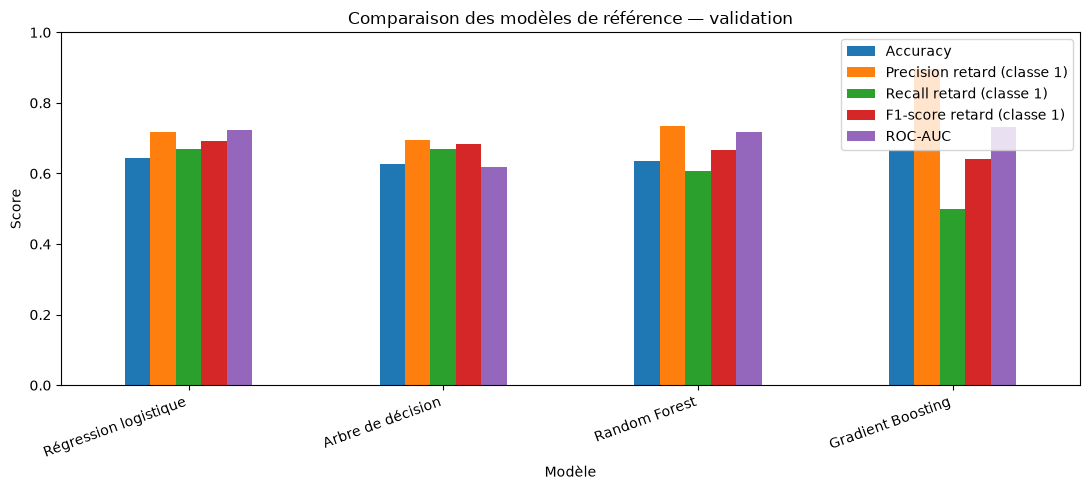

\nMatrice de confusion — Régression logistique


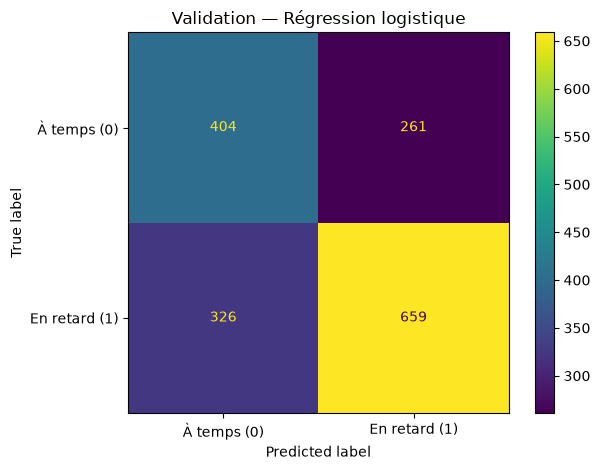

\nMatrice de confusion — Arbre de décision


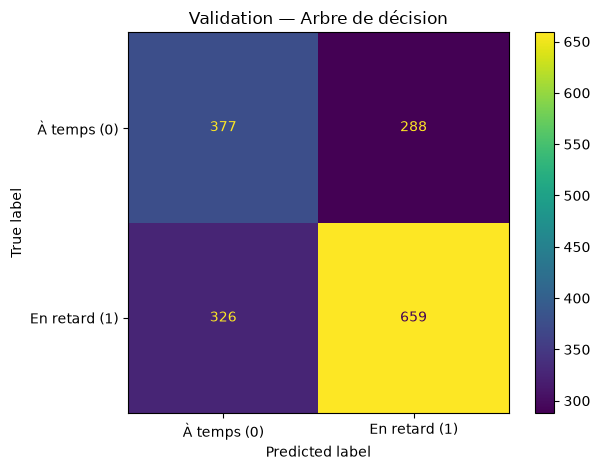

\nMatrice de confusion — Random Forest


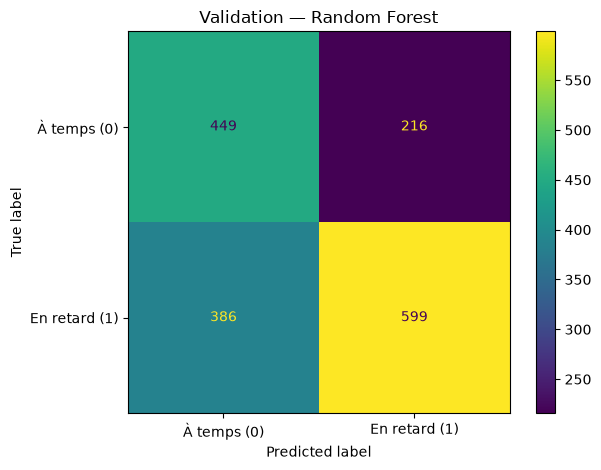

\nMatrice de confusion — Gradient Boosting


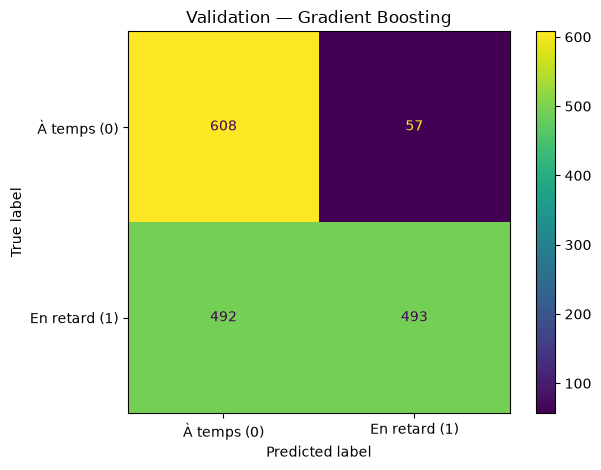

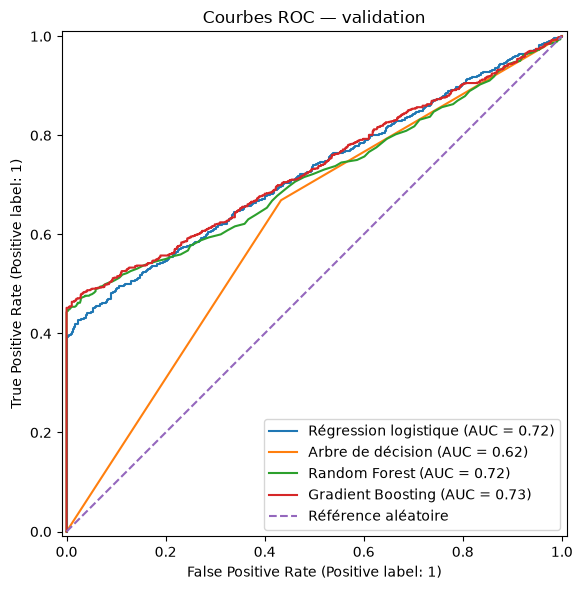

In [10]:
metrics_baseline = [
    "Accuracy", "Precision retard (classe 1)",
    "Recall retard (classe 1)", "F1-score retard (classe 1)", "ROC-AUC"
]
baseline_df[metrics_baseline].plot(kind="bar", figsize=(11, 5))
plt.title("Comparaison des modèles de référence — validation")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparaison_modeles_reference.png"), dpi=150)
plt.show()

for name, model in baseline_fitted.items():
    print("\\nMatrice de confusion —", name)
    ConfusionMatrixDisplay.from_estimator(
        model, X_valid, y_valid,
        labels=[0, 1],
        display_labels=["À temps (0)", "En retard (1)"],
        values_format="d"
    )
    plt.title(f"Validation — {name}")
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in baseline_fitted.items():
    RocCurveDisplay.from_estimator(model, X_valid, y_valid, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Référence aléatoire")
ax.set_title("Courbes ROC — validation")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "courbes_roc_validation.png"), dpi=150)
plt.show()


## 8. Optimisation des hyperparamètres par validation croisée

La recherche utilise uniquement `X_train` et `y_train`. Le score de sélection est le F1-score de la classe positive 1 (retard). La validation sert ensuite à comparer les modèles optimisés.

In [11]:
param_grids = {
    "Régression logistique": {
        "model": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        "params": {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}
    },
    "Arbre de décision": {
        "model": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "params": {"model__max_depth": [4, 8, 12, None], "model__min_samples_leaf": [3, 5, 10, 20], "model__class_weight": [None, "balanced"]}
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "params": {"model__n_estimators": [100, 200], "model__max_depth": [8, 15, None], "model__min_samples_leaf": [3, 5, 10], "model__class_weight": [None, "balanced"]}
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "params": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3], "model__min_samples_leaf": [5, 10]}
    }
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
optimized_models = {}
optimization_rows = []

for name, config in param_grids.items():
    print("Optimisation :", name)
    pipe = Pipeline([("preprocessor", preprocessor), ("model", config["model"])])
    search = GridSearchCV(pipe, config["params"], scoring="f1", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_
    valid_pred = best_pipe.predict(X_valid)
    valid_prob = best_pipe.predict_proba(X_valid)[:, 1]
    row = evaluate_predictions(y_valid, valid_pred, valid_prob)
    row.update({"Modèle": name, "F1-score CV": search.best_score_, "Meilleurs paramètres": search.best_params_})
    optimization_rows.append(row)
    optimized_models[name] = best_pipe

optimization_df = pd.DataFrame(optimization_rows).sort_values("F1-score retard (classe 1)", ascending=False)
display(optimization_df.round(4))

Optimisation : Régression logistique
Optimisation : Arbre de décision
Optimisation : Random Forest
Optimisation : Gradient Boosting


,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC,Modèle,F1-score CV,Meilleurs paramètres
0,0.6558,0.7174,0.6985,0.7078,0.7310,Régression logistique,0.7009,"{'model__C': 0.01, 'model__class_weight': None}"
3,0.6861,0.8060,0.6244,0.7037,0.7578,Gradient Boosting,0.6922,"{'model__learning_rate': 0.03, 'model__max_dep..."
1,0.6327,0.7089,0.6528,0.6797,0.6613,Arbre de décision,0.7090,"{'model__class_weight': 'balanced', 'model__ma..."
2,0.6455,0.7674,0.5827,0.6624,0.7188,Random Forest,0.6868,"{'model__class_weight': None, 'model__max_dept..."


### Recherche complémentaire par Random Search\nRandom Search explore un échantillon de combinaisons d'hyperparamètres de Random Forest. Il utilise uniquement l'entraînement et la validation croisée ; la validation indépendante sert à mesurer le résultat.\n

In [12]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

random_params = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": [None, 8, 12, 15, 20],
    "model__min_samples_split": randint(2, 16),
    "model__min_samples_leaf": randint(1, 11),
    "model__class_weight": [None, "balanced"]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=random_params,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)
random_search.fit(X_train, y_train)

random_best_model = random_search.best_estimator_
random_valid_pred = random_best_model.predict(X_valid)
random_valid_prob = random_best_model.predict_proba(X_valid)[:, 1]
random_metrics = evaluate_predictions(y_valid, random_valid_pred, random_valid_prob)

random_row = {
    **random_metrics,
    "Modèle": "Random Forest — Random Search",
    "F1-score CV": random_search.best_score_,
    "Meilleurs paramètres": random_search.best_params_
}
optimization_df = pd.concat(
    [optimization_df, pd.DataFrame([random_row])],
    ignore_index=True
)
optimized_models["Random Forest — Random Search"] = random_best_model

optimization_df = optimization_df.sort_values(
    "F1-score retard (classe 1)", ascending=False
).reset_index(drop=True)

print("Meilleure configuration Random Search :", random_search.best_params_)
display(optimization_df.round(4))


Meilleure configuration Random Search : {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 6, 'model__n_estimators': 379}


,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC,Modèle,F1-score CV,Meilleurs paramètres
0,0.6558,0.7174,0.6985,0.7078,0.7310,Régression logistique,0.7009,"{'model__C': 0.01, 'model__class_weight': None}"
1,0.6861,0.8060,0.6244,0.7037,0.7578,Gradient Boosting,0.6922,"{'model__learning_rate': 0.03, 'model__max_dep..."
2,0.6327,0.7089,0.6528,0.6797,0.6613,Arbre de décision,0.7090,"{'model__class_weight': 'balanced', 'model__ma..."
3,0.6509,0.7709,0.5909,0.6690,0.7172,Random Forest — Random Search,0.6884,"{'model__class_weight': None, 'model__max_dept..."
4,0.6455,0.7674,0.5827,0.6624,0.7188,Random Forest,0.6868,"{'model__class_weight': None, 'model__max_dept..."


## 9. Sélection du meilleur modèle sur validation

Le modèle est choisi uniquement à partir du F1-score de validation, sans consulter le jeu de test.

In [13]:
best_row = optimization_df.loc[optimization_df["F1-score retard (classe 1)"].idxmax()]
best_model_name = best_row["Modèle"]
best_model = optimized_models[best_model_name]
best_params = best_row["Meilleurs paramètres"]

print("Meilleur modèle sur validation :", best_model_name)
print("F1-score validation :", round(best_row["F1-score retard (classe 1)"], 4))
print("Meilleurs paramètres :", best_params)

Meilleur modèle sur validation : Régression logistique
F1-score validation : 0.7078
Meilleurs paramètres : {'model__C': 0.01, 'model__class_weight': None}


## 10. Choix du seuil sur validation

Le seuil 0,50 est conservé comme référence. Un autre seuil peut être choisi sur la validation pour maximiser le F1-score de la classe 1. Le seuil choisi sera ensuite figé avant l’évaluation sur le test.

In [14]:
# Le seuil est choisi exclusivement sur le jeu de validation.
# Politique métier provisoire : viser au moins 90 % de rappel sur les retards,
# puis retenir le seuil qui donne la meilleure précision parmi les seuils admissibles.
# Cette cible (85 %) est un paramètre ajustable avec l'équipe métier.
MIN_RECALL_TARGET = 0.85

valid_probabilities = best_model.predict_proba(X_valid)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(
    y_valid, valid_probabilities, pos_label=1
)

# precision_recall_curve renvoie un point de plus pour précision/rappel que pour thresholds.
pr_table = pd.DataFrame({
    "Seuil": thresholds,
    "Precision retard (classe 1)": precision_values[:-1],
    "Recall retard (classe 1)": recall_values[:-1]
})
pr_table["F1-score retard (classe 1)"] = (
    2 * pr_table["Precision retard (classe 1)"] * pr_table["Recall retard (classe 1)"]
    / (pr_table["Precision retard (classe 1)"] + pr_table["Recall retard (classe 1)"] + 1e-12)
)

# Comparaison des politiques de rappel (85 %, 90 %, 95 %).
policy_rows = []
for recall_target in [0.85, 0.90, 0.95]:
    eligible = pr_table[pr_table["Recall retard (classe 1)"] >= recall_target]
    if eligible.empty:
        policy_rows.append({
            "Rappel minimal visé": recall_target,
            "Seuil": np.nan,
            "Précision retard (classe 1)": np.nan,
            "Rappel retard (classe 1)": np.nan,
            "F1-score retard (classe 1)": np.nan,
            "Faux positifs": np.nan,
            "Faux négatifs": np.nan,
            "Statut": "Objectif non atteignable sur validation"
        })
        continue

    # Parmi les seuils qui respectent le rappel minimal, choisir la meilleure précision.
    chosen = eligible.sort_values(
        ["Precision retard (classe 1)", "Seuil"],
        ascending=[False, False]
    ).iloc[0]
    pred = (valid_probabilities >= float(chosen["Seuil"])).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
    policy_rows.append({
        "Rappel minimal visé": recall_target,
        "Seuil": float(chosen["Seuil"]),
        "Precision retard (classe 1)": float(chosen["Precision retard (classe 1)"]),
        "Recall retard (classe 1)": float(chosen["Recall retard (classe 1)"]),
        "F1-score retard (classe 1)": float(chosen["F1-score retard (classe 1)"]),
        "Faux positifs": int(fp),
        "Faux négatifs": int(fn),
        "Statut": "Atteint"
    })

policy_comparison = pd.DataFrame(policy_rows)
display(policy_comparison.round(4))

selected_policy = policy_comparison[
    policy_comparison["Rappel minimal visé"] == MIN_RECALL_TARGET
].iloc[0]

if selected_policy["Statut"] == "Atteint":
    best_threshold = float(selected_policy["Seuil"])
    threshold_policy_status = f"Rappel minimal {MIN_RECALL_TARGET:.0%} atteint"
else:
    # Repli explicite si la cible n'est pas atteignable : maximiser le rappel.
    best_idx = int(pr_table["Recall retard (classe 1)"].idxmax())
    best_threshold = float(pr_table.loc[best_idx, "Seuil"])
    threshold_policy_status = (
        f"Cible {MIN_RECALL_TARGET:.0%} non atteignable; seuil de rappel maximal utilisé"
    )

best_valid_pred = (valid_probabilities >= best_threshold).astype(int)
best_valid_metrics = evaluate_predictions(y_valid, best_valid_pred, valid_probabilities)
tn, fp, fn, tp = confusion_matrix(y_valid, best_valid_pred, labels=[0, 1]).ravel()

print("Politique de seuil :", threshold_policy_status)
print(f"Seuil retenu sur validation : {best_threshold:.4f}")
print(f"Précision retard validation : {best_valid_metrics['Precision retard (classe 1)']:.4f}")
print(f"Rappel retard validation : {best_valid_metrics['Recall retard (classe 1)']:.4f}")
print(f"F1-score retard validation : {best_valid_metrics['F1-score retard (classe 1)']:.4f}")
print(f"Fausses alertes (FP) validation : {fp}")
print(f"Retards manqués (FN) validation : {fn}")

# Tableau détaillé de quelques seuils de référence et du seuil retenu.
threshold_rows = []
candidate_thresholds = sorted(set([0.35, 0.40, 0.45, 0.50, 0.55, 0.60, best_threshold]))
for threshold in candidate_thresholds:
    pred = (valid_probabilities >= threshold).astype(int)
    m = evaluate_predictions(y_valid, pred, valid_probabilities)
    m["Seuil"] = threshold
    tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
    m["Faux positifs"] = int(fp)
    m["Faux négatifs"] = int(fn)
    m["Vrais positifs"] = int(tp)
    threshold_rows.append(m)
threshold_df = pd.DataFrame(threshold_rows).sort_values("Seuil")
display(threshold_df[[
    "Seuil", "Precision retard (classe 1)", "Recall retard (classe 1)",
    "F1-score retard (classe 1)", "Faux positifs", "Faux négatifs"
]].round(4))

policy_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "comparaison_politiques_seuil_validation.csv"),
    index=False
)

,Rappel minimal visé,Seuil,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),Faux positifs,Faux négatifs,Statut
0,0.85,0.4345,0.6452,0.8528,0.7346,462,145,Atteint
1,0.90,0.4081,0.6265,0.9025,0.7396,530,96,Atteint
2,0.95,0.3673,0.6086,0.9503,0.7420,602,49,Atteint


Politique de seuil : Rappel minimal 85% atteint
Seuil retenu sur validation : 0.4345
Précision retard validation : 0.6452
Rappel retard validation : 0.8528
F1-score retard validation : 0.7346
Fausses alertes (FP) validation : 462
Retards manqués (FN) validation : 145


,Seuil,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),Faux positifs,Faux négatifs
0,0.3500,0.6053,0.9685,0.7450,622,31
1,0.4000,0.6198,0.9137,0.7386,552,85
2,0.4345,0.6452,0.8528,0.7346,462,145
3,0.4500,0.6547,0.8162,0.7266,424,181
4,0.5000,0.7174,0.6985,0.7078,271,297
5,0.5500,0.7901,0.5695,0.6619,149,424
6,0.6000,0.8856,0.4792,0.6219,61,513


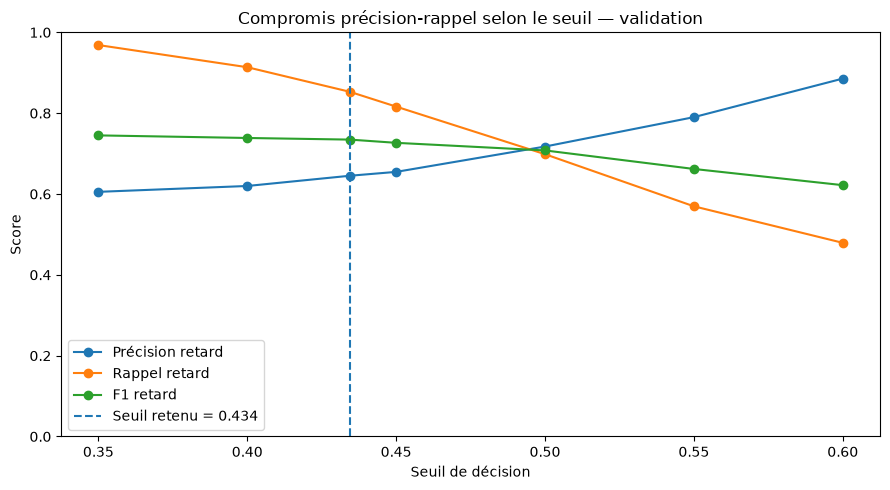

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_df["Seuil"], threshold_df["Precision retard (classe 1)"], marker="o", label="Précision retard")
plt.plot(threshold_df["Seuil"], threshold_df["Recall retard (classe 1)"], marker="o", label="Rappel retard")
plt.plot(threshold_df["Seuil"], threshold_df["F1-score retard (classe 1)"], marker="o", label="F1 retard")
plt.axvline(best_threshold, linestyle="--", label=f"Seuil retenu = {best_threshold:.3f}")
plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Compromis précision-rappel selon le seuil — validation")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "compromis_seuil_validation.png"), dpi=150)
plt.show()


## 11. Évaluation finale sur le jeu de test

Le jeu de test n’est utilisé qu’ici, après la sélection du modèle et du seuil. Les deux seuils (0,50 et seuil optimisé) sont présentés pour rendre le compromis visible.

Modèle retenu : Régression logistique
Politique de seuil : Rappel minimal 85% atteint


,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC,Faux positifs,Faux négatifs
"Seuil standard 0,50",0.6255,0.6819,0.6972,0.6894,0.7124,320,298
Seuil retenu 0.434,0.6073,0.6271,0.8425,0.7190,0.7124,493,155


Rapport de classification — seuil retenu
               precision    recall  f1-score   support

  À temps (0)       0.53      0.26      0.35       666
En retard (1)       0.63      0.84      0.72       984

     accuracy                           0.61      1650
    macro avg       0.58      0.55      0.53      1650
 weighted avg       0.59      0.61      0.57      1650



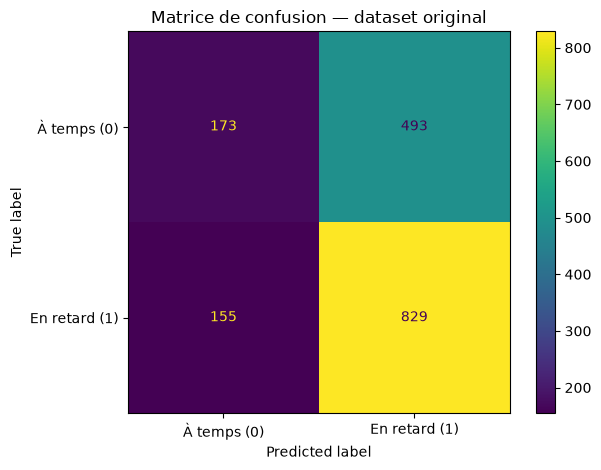

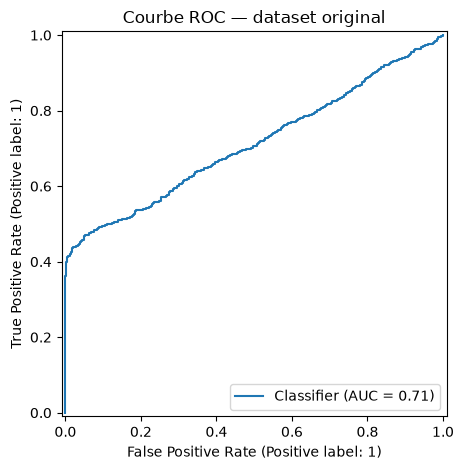

In [16]:
test_probabilities = best_model.predict_proba(X_test)[:, 1]
predictions_050 = (test_probabilities >= 0.50).astype(int)
predictions_tuned = (test_probabilities >= best_threshold).astype(int)

metrics_050 = evaluate_predictions(y_test, predictions_050, test_probabilities)
metrics_tuned = evaluate_predictions(y_test, predictions_tuned, test_probabilities)

tn50, fp50, fn50, tp50 = confusion_matrix(y_test, predictions_050, labels=[0, 1]).ravel()
tn, fp, fn, tp = confusion_matrix(y_test, predictions_tuned, labels=[0, 1]).ravel()
metrics_050.update({"Faux positifs": int(fp50), "Faux négatifs": int(fn50)})
metrics_tuned.update({"Faux positifs": int(fp), "Faux négatifs": int(fn)})

test_comparison = pd.DataFrame(
    [metrics_050, metrics_tuned],
    index=["Seuil standard 0,50", f"Seuil retenu {best_threshold:.3f}"]
)
print("Modèle retenu :", best_model_name)
print("Politique de seuil :", threshold_policy_status)
display(test_comparison.round(4))

print("Rapport de classification — seuil retenu")
print(classification_report(
    y_test, predictions_tuned, labels=[0, 1],
    target_names=["À temps (0)", "En retard (1)"], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions_tuned, labels=[0, 1],
    display_labels=["À temps (0)", "En retard (1)"], values_format="d"
)
plt.title("Matrice de confusion — dataset original")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "matrice_confusion_test_original.png"), dpi=150)
plt.show()

RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("Courbe ROC — dataset original")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "courbe_roc_test_original.png"), dpi=150)
plt.show()

final_metrics = metrics_tuned.copy()
test_comparison.to_csv(os.path.join(OUTPUT_DIR, "resultats_test_original.csv"))

## 12. Importance des variables originales

L’importance par permutation est calculée sur la validation. Elle mesure la dépendance prédictive du modèle aux variables, sans démontrer de causalité.

,Variable,Importance moyenne,Écart-type
9,Weight_in_gms,0.0234,0.0069
8,Discount_offered,0.0141,0.0087
1,Mode_of_Shipment,0.0025,0.0010
3,Customer_rating,0.0015,0.0021
0,Warehouse_block,0.0010,0.0022
6,Product_importance,0.0009,0.0025
5,Prior_purchases,-0.0001,0.0048
7,Gender,-0.0008,0.0015
4,Cost_of_the_Product,-0.0014,0.0036
2,Customer_care_calls,-0.0032,0.0020


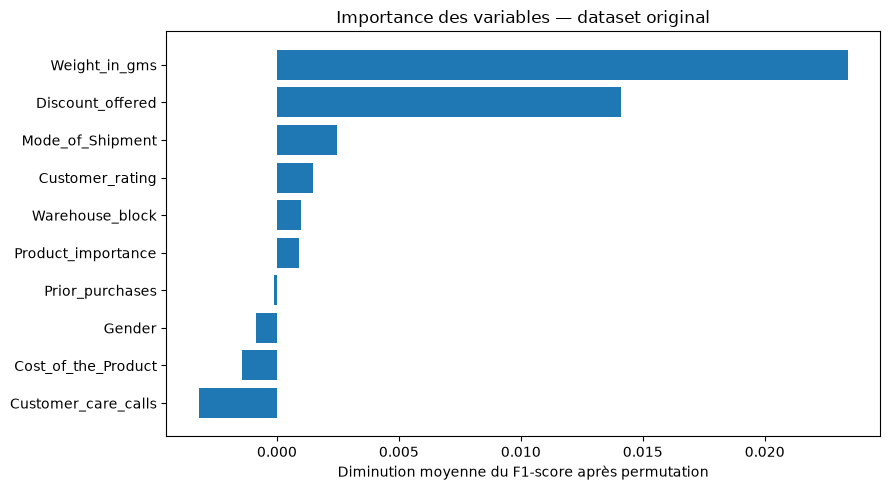

In [17]:
permutation = permutation_importance(
    best_model, X_valid, y_valid,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=-1
)
importance_df = pd.DataFrame({
    "Variable": original_features,
    "Importance moyenne": permutation.importances_mean,
    "Écart-type": permutation.importances_std
}).sort_values("Importance moyenne", ascending=False)
display(importance_df.round(4))

plot_df = importance_df.sort_values("Importance moyenne").tail(10)
plt.figure(figsize=(9, 5))
plt.barh(plot_df["Variable"], plot_df["Importance moyenne"])
plt.xlabel("Diminution moyenne du F1-score après permutation")
plt.title("Importance des variables — dataset original")
plt.tight_layout()
plt.show()

## 13. Explication des prédictions avec SHAP\nSHAP estime la contribution des variables originales aux probabilités prédites de retard. L'explication utilise un échantillon d'entraînement comme référence et des observations de validation ; le jeu de test n'est pas utilisé.\n

Version SHAP : 0.54.1


c:\Users\nadia\OneDrive - Collège la Cité\Bureau\Tous_dossiers\Session3\Projet_IA_M&D\Delais_livraison\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\nadia\OneDrive - Collège la Cité\Bureau\Tous_dossiers\Session3\Projet_IA_M&D\Delais_livraison\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\nadia\OneDrive - Collège la Cité\Bureau\Tous_dossiers\Session3\Projet_IA_M&D\Delais_livraison\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\nadia\OneDrive - Collège la Cité\Bureau\Tous_dossiers\Session3\Projet_IA_M&D\Delais_livraison\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, b

Dimensions des valeurs SHAP : (60, 19)
Nombre de colonnes après encodage : 19


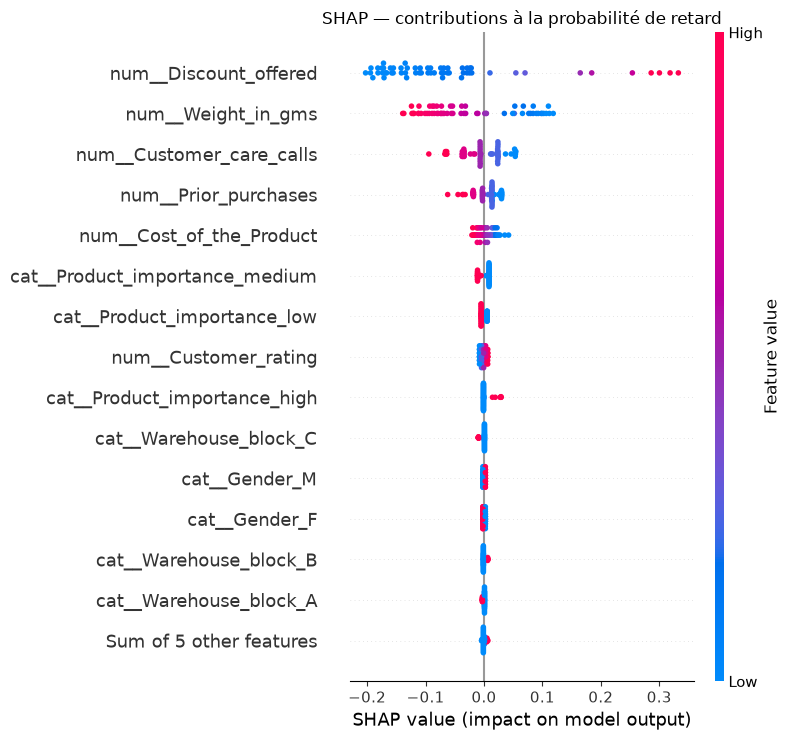

,Variable transformée,Importance SHAP moyenne
4,num__Discount_offered,0.12636
5,num__Weight_in_gms,0.07674
0,num__Customer_care_calls,0.03090
3,num__Prior_purchases,0.01787
2,num__Cost_of_the_Product,0.01257
16,cat__Product_importance_medium,0.00898
15,cat__Product_importance_low,0.00482
1,num__Customer_rating,0.00425
14,cat__Product_importance_high,0.00367
8,cat__Warehouse_block_C,0.00233


In [18]:
try:
    import shap
except ImportError:
    %pip install -q shap
    import shap

print("Version SHAP :", shap.__version__)

# Échantillons limités pour contrôler le temps de calcul
background = X_train.sample(n=min(40, len(X_train)), random_state=RANDOM_STATE)
X_explain = X_valid.sample(n=min(60, len(X_valid)), random_state=RANDOM_STATE)

preprocessor_final = best_model.named_steps["preprocessor"]
model_final = best_model.named_steps["model"]

background_transformed = preprocessor_final.transform(background)
X_explain_transformed = preprocessor_final.transform(X_explain)

if hasattr(background_transformed, "toarray"):
    background_transformed = background_transformed.toarray()
if hasattr(X_explain_transformed, "toarray"):
    X_explain_transformed = X_explain_transformed.toarray()

feature_names_shap = preprocessor_final.get_feature_names_out()
background_df = pd.DataFrame(background_transformed, columns=feature_names_shap)
X_explain_df = pd.DataFrame(X_explain_transformed, columns=feature_names_shap)

def predict_delay_probability(data):
    return model_final.predict_proba(data)[:, 1]

masker = shap.maskers.Independent(background_df)
explainer = shap.Explainer(
    predict_delay_probability, masker, algorithm="permutation"
)
shap_values = explainer(
    X_explain_df,
    max_evals=max(2 * len(feature_names_shap) + 1, 100)
)

print("Dimensions des valeurs SHAP :", shap_values.values.shape)
print("Nombre de colonnes après encodage :", len(feature_names_shap))

plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP — contributions à la probabilité de retard")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "shap_beeswarm_original.png"), dpi=150, bbox_inches="tight")
plt.show()

shap_importance = pd.DataFrame({
    "Variable transformée": feature_names_shap,
    "Importance SHAP moyenne": np.abs(shap_values.values).mean(axis=0)
}).sort_values("Importance SHAP moyenne", ascending=False)

display(shap_importance.head(20).round(5))
shap_importance.to_csv(
    os.path.join(OUTPUT_DIR, "importance_shap_original.csv"),
    index=False
)


## 13. Sauvegarde du modèle et des résultats

Le paquet sauvegardé contient le pipeline complet, les variables originales, la convention de la cible et le seuil de décision.

In [19]:
model_package = {
    "model": best_model,
    "features": original_features,
    "target": TARGET,
    "positive_class": 1,
    "class_definition": {"1": "En retard", "0": "À temps"},
    "model_name": best_model_name,
    "configuration": best_params,
    "decision_threshold": best_threshold,
    "threshold_policy": threshold_policy_status,
    "minimum_recall_target": MIN_RECALL_TARGET,
    "dataset_version": "Original.csv",
    "random_state": RANDOM_STATE
}

joblib.dump(model_package, os.path.join(OUTPUT_DIR, "shopexpress_modele_original.joblib"))
optimization_df.to_csv(os.path.join(OUTPUT_DIR, "resultats_optimisation_original.csv"), index=False)
test_comparison.to_csv(os.path.join(OUTPUT_DIR, "resultats_test_original.csv"))
importance_df.to_csv(os.path.join(OUTPUT_DIR, "importance_variables_original.csv"), index=False)

print("Fichiers sauvegardés dans :", os.path.abspath(OUTPUT_DIR))


Fichiers sauvegardés dans : c:\Users\nadia\OneDrive - Collège la Cité\Bureau\Tous_dossiers\Session3\Projet_IA_M&D\Delais_livraison\resultats_shopexpress


## 14. Suivi des expériences avec MLflow sur DagsHub — Nadia

Cette expérience est envoyée au dépôt DagsHub `nadiagouroubera40-debug/Delais_de_Livraison`. Vous devez avoir un accès contributeur à ce dépôt. L’authentification est gérée par `dagshub.init()` ; si DagsHub demande une autorisation, suivez l’invite. **Ne mettez jamais votre token dans le notebook ni sur GitHub.**

In [20]:
import dagshub
import mlflow
import mlflow.sklearn

DAGSHUB_OWNER = "nadiagouroubera40-debug"
DAGSHUB_REPO = "Delais_de_Livraison"
MLFLOW_EXPERIMENT = "ShopExpress_Original_Dataset"

# Configure le tracking distant et l'authentification DagsHub.
dagshub.init(repo_owner=DAGSHUB_OWNER, repo_name=DAGSHUB_REPO, mlflow=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Expérience :", MLFLOW_EXPERIMENT)

Accessing as nadiagouroubera40-debug

Initialized MLflow to track repo "nadiagouroubera40-debug/Delais_de_Livraison"

Repository nadiagouroubera40-debug/Delais_de_Livraison initialized!

Tracking URI : https://dagshub.com/nadiagouroubera40-debug/Delais_de_Livraison.mlflow
Expérience : ShopExpress_Original_Dataset


In [21]:
import numpy as np

colonnes_metriques = [
    "Accuracy",
    "Precision retard (classe 1)",
    "Recall retard (classe 1)",
    "F1-score retard (classe 1)",
    "ROC-AUC",
    "F1-score CV"
]

for colonne in colonnes_metriques:
    print(f"\n{colonne}")
    print(optimization_df[colonne])

    valeurs = optimization_df[colonne].astype(float)

    if not np.isfinite(valeurs).all():
        print("ATTENTION : valeurs NaN ou infinies détectées")
    else:
        print("OK : valeurs numériques valides")


Accuracy
0    0.655758
1    0.686061
2    0.632727
3    0.650909
4    0.645455
Name: Accuracy, dtype: float64
OK : valeurs numériques valides

Precision retard (classe 1)
0    0.717414
1    0.806029
2    0.708931
3    0.770861
4    0.767380
Name: Precision retard (classe 1), dtype: float64
OK : valeurs numériques valides

Recall retard (classe 1)
0    0.698477
1    0.624365
2    0.652792
3    0.590863
4    0.582741
Name: Recall retard (classe 1), dtype: float64
OK : valeurs numériques valides

F1-score retard (classe 1)
0    0.707819
1    0.703661
2    0.679704
3    0.668966
4    0.662435
Name: F1-score retard (classe 1), dtype: float64
OK : valeurs numériques valides

ROC-AUC
0    0.731045
1    0.757757
2    0.661299
3    0.717205
4    0.718843
Name: ROC-AUC, dtype: float64
OK : valeurs numériques valides

F1-score CV
0    0.700876
1    0.692191
2    0.708964
3    0.688387
4    0.686821
Name: F1-score CV, dtype: float64
OK : valeurs numériques valides


In [22]:
import re

def nettoyer_nom_metrique(nom):
    nom = nom.lower()
    nom = re.sub(r"[^a-zA-Z0-9_]", "_", nom)
    nom = re.sub(r"_+", "_", nom)
    return nom.strip("_")[:100]

print("Fonction de nettoyage prête !")

Fonction de nettoyage prête !


In [23]:
fichiers_a_enregistrer = [
    "shopexpress_modele_original.joblib",
    "resultats_optimisation_original.csv",
    "resultats_test_original.csv",
    "importance_variables_original.csv",
    "importance_shap_original.csv",
    "shap_beeswarm_original.png",
    "comparaison_modeles_reference.png",
    "courbes_roc_validation.png",
    "compromis_seuil_validation.png",
    "comparaison_politiques_seuil_validation.csv",
    "matrice_confusion_test_original.png",
    "courbe_roc_test_original.png"
]

fichiers_a_enregistrer = [
    os.path.join(OUTPUT_DIR, fichier)
    for fichier in fichiers_a_enregistrer
    if os.path.isfile(os.path.join(OUTPUT_DIR, fichier))
]

print("Fichiers disponibles pour MLflow :")
for fichier in fichiers_a_enregistrer:
    print("-", fichier)


Fichiers disponibles pour MLflow :
- resultats_shopexpress\shopexpress_modele_original.joblib
- resultats_shopexpress\resultats_optimisation_original.csv
- resultats_shopexpress\resultats_test_original.csv
- resultats_shopexpress\importance_variables_original.csv
- resultats_shopexpress\importance_shap_original.csv
- resultats_shopexpress\shap_beeswarm_original.png
- resultats_shopexpress\comparaison_modeles_reference.png
- resultats_shopexpress\courbes_roc_validation.png
- resultats_shopexpress\compromis_seuil_validation.png
- resultats_shopexpress\comparaison_politiques_seuil_validation.csv
- resultats_shopexpress\matrice_confusion_test_original.png
- resultats_shopexpress\courbe_roc_test_original.png


In [24]:
with mlflow.start_run(
    run_name=f"Original_FINAL_{best_model_name}"
):

    mlflow.log_param("dataset", "Original.csv")
    mlflow.log_param("model", best_model_name)
    mlflow.log_param("target", TARGET)
    mlflow.log_param("positive_class", 1)
    mlflow.log_param("decision_threshold", float(best_threshold))
    mlflow.log_param("minimum_recall_target", float(MIN_RECALL_TARGET))
    mlflow.log_param("threshold_policy", threshold_policy_status)

    mlflow.log_param(
        "features",
        json.dumps(original_features, ensure_ascii=True)
    )

    mlflow.log_param(
        "best_params",
        json.dumps(best_params, default=str)
    )

    mlflow.log_param(
        "split",
        "70_train_15_validation_15_test"
    )

    for metric, value in metrics_tuned.items():
        valeur = float(value)

        if np.isfinite(valeur):
            mlflow.log_metric(
                nettoyer_nom_metrique(metric),
                valeur
            )

    for fichier in fichiers_a_enregistrer:
        mlflow.log_artifact(fichier)

    # Correction de la sérialisation
    mlflow.sklearn.log_model(
        sk_model=best_model,
        artifact_path="model",
        skops_trusted_types=["numpy.dtype"]
    )

    print("Modèle final enregistré avec succès !")

2026/11/20 12:45:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Modèle final enregistré avec succès !
🏃 View run Original_FINAL_Régression logistique at: https://dagshub.com/nadiagouroubera40-debug/Delais_de_Livraison.mlflow/#/experiments/1/runs/7f41e32f9df849eabc90c7d2532ad7b9
🧪 View experiment at: https://dagshub.com/nadiagouroubera40-debug/Delais_de_Livraison.mlflow/#/experiments/1


## Bilan de l’expérience originale

Après exécution complète, consigner ici :
- le meilleur modèle sélectionné sur validation ;
- le seuil retenu selon la politique de rappel ;
- précision, rappel, F1-score, ROC-AUC, faux positifs et faux négatifs sur le test ;
- les variables les plus importantes ;
- les limites et les éventuels risques de fuite de données.

**Interprétation métier :** la classe positive est `1 = en retard`. La politique par défaut vise
un rappel minimal de 90 % sur validation, puis maximise la précision parmi les seuils qui
respectent cette contrainte. Les objectifs de 85 %, 90 % et 95 % sont comparés. Si 90 %
n'est pas atteignable, le notebook l'indique et utilise le seuil donnant le rappel maximal.
Le jeu de test reste isolé jusqu'à l'évaluation finale.

**Attention au moment de prédiction :** avant de présenter ce modèle comme une prédiction
« dès l'expédition », vérifier que chaque variable (notamment `Customer_care_calls`,
`Customer_rating` et `Discount_offered`) est réellement connue à cet instant. Si une variable
n'est connue qu'après l'expédition ou après une interaction client, elle doit être exclue du
modèle de mise en production.

**Comparaison avec le jeu enrichi :** ne comparer les modèles qu'avec le même découpage,
la même définition de la cible et les mêmes règles d'évaluation. Les colonnes synthétiques
ne sont pas utilisées dans ce notebook.